# Introduction


## About this Practical Exercise

This notebook is the second part of the classification exercise we started for the analysis of high-dimensional transcriptomic data, where the number of features (*p* genes) far exceeds the number of samples (*n*, patients).

This time, we will use a dimensionality reduction and classification approach, different from the previous approach where we did variable selection + classification.

## What are we going to do

We will focus on the overall machine learning pipeline, emphasizing methodological choices and their implications.

# Environment Setup and Data Loading

## Load and Inspect Gene Expression Data

**Action:** Run the following code chunk to load the expression data.

In [ ]:
import os
import zipfile
import requests
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, cross_validate
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.decomposition import PCA
from umap import UMAP
from sklearn.metrics import accuracy_score, roc_auc_score, confusion_matrix, roc_curve, cohen_kappa_score, make_scorer, recall_score
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.utils import resample
from sklearn.pipeline import Pipeline
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import HTML
from matplotlib.lines import Line2D

In [ ]:
!pip install pyreadr
import pyreadr

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 788.3/788.3 kB 41.5 MB/s eta 0:00:00


### To use the shared data in this folder:

Go to the shared folder biotrain2026

Select Organize --> Add shortcut

<img src="https://drive.google.com/uc?export=view&id=14UNjWLkh_HR75FFTDEIB4ZyomN3eTyr9" alt="img1" width="80%">

Go to All locations
Select My Drive, then Add

<img src="https://drive.google.com/uc?export=view&id=1_oB11wBHkGzfHoq0KgCjufYEno9AU4JG" alt="img2" width="40%">

Mount your local drive:

In [ ]:
from google.colab import drive
import os
drive.mount('/content/drive/', force_remount=True)

Mounted at /content/drive/


Change the working directory.

You should change to $\verb|/content/drive/My Drive/EMBL-EBI 2026. Gene expression group/|$

In [ ]:
os.chdir('/content/drive/My Drive/Cursos/metagenomica/EMBL-EBI 2026. Gene expression group/')
!ls

Code  Data  Info  References


In [ ]:
# load the data
exp = pyreadr.read_r("Data/gene_expresion_prostate_cancer.RDS")[None]

In [ ]:
print("Shape: ",exp.shape)

Shape:  (243, 20530)


The output of `dim(exp)` reveals the high-dimensionality of our dataset: 243 samples and 20,530 gene features. This `d >> n` (many more features than samples) scenario is typical in genomics and is a primary motivation for using machine learning and feature selection.

## Load and Inspect Phenotypic Data

Next, we load the clinical data for the same cohort of patients. This table contains potential predictor variables and our outcome variable of interest.

**Action:** Run the following code chunk to load and inspect the phenotype data.


In [ ]:
pheno = pyreadr.read_r("Data/pheno_prostate_cancer.RDS")[None]
#pheno["recurrence.3y"] = pheno["recurrence.3y"].astype(int).astype("category")
pheno["recurrence.3y"] = (
    pheno["recurrence.3y"]
    .astype(int)
    .map({
        0: "No recurrence",
        1: "Recurrence"
    })
    .astype("category")
)
pheno.info()

<class 'pandas.core.frame.DataFrame'>
Index: 243 entries, TCGA-2A-A8VO-01 to TCGA-ZG-A9L9-01
Data columns (total 11 columns):
 #   Column                               Non-Null Count  Dtype   
---  ------                               --------------  -----   
 0   age                                  243 non-null    int32   
 1   initial_weight                       128 non-null    object  
 2   initial_pathologic_diagnosis_method  243 non-null    object  
 3   histological_type                    243 non-null    object  
 4   ISUP_group                           243 non-null    category
 5   pathologic_T_simple                  241 non-null    category
 6   laterality                           240 non-null    object  
 7   PFI                                  243 non-null    int32   
 8   PFI.time                             243 non-null    int32   
 9   PSA                                  234 non-null    float64 
 10  recurrence.3y                        243 non-null    category
dty

The output shows several key clinical variables, including `age`, `ISUP_group`, `pathologic_T_simple`, and `PSA`. Crucially, it also contains our target variable for classification: `recurrence.3y`, coded as `1` for recurrence and `0` for no recurrence within three years.

## Generate a Baseline Clinical Summary

Standard practice in clinical research is to generate a descriptive summary of the patient cohort's baseline characteristics. This "Table 1" provides an overview of the distribution of key variables stratified by the outcome. It allows us to understand the composition of our cohort.

**Action:** Run the following chunk to generate the summary table.

In [ ]:
from IPython.display import display

# Select clinical variables
vars_table1 = ["age", "PSA", "ISUP_group", "pathologic_T_simple", "recurrence.3y"]
pheno_table = pheno[vars_table1].copy()

# Continuous and categorical variables
continuous_vars = ["age", "PSA"]
categorical_vars = ["ISUP_group", "pathologic_T_simple", "recurrence.3y"]

summary_rows = []

# Summary of continuous variables: mean (SD)
for col in continuous_vars:
    mean = pheno_table[col].mean()
    sd = pheno_table[col].std()
    summary_rows.append({
        "Variable": col,
        "Summary": f"{mean:.2f} ({sd:.2f})"
    })

# Summary of categorical variables: n (%)
for col in categorical_vars:
    counts = pheno_table[col].value_counts(dropna=False)
    total = len(pheno_table)

    for level, n in counts.items():
        pct = 100 * n / total
        summary_rows.append({
            "Variable": f"{col}: {level}",
            "Summary": f"{n} ({pct:.1f}%)"
        })

summary_table = pd.DataFrame(summary_rows)
display(HTML(summary_table.to_html(index=False)))

Variable,Summary
age,60.73 (6.30)
PSA,11.72 (13.53)
ISUP_group: 5,83 (34.2%)
ISUP_group: 2,64 (26.3%)
ISUP_group: 3,49 (20.2%)
ISUP_group: 4,31 (12.8%)
ISUP_group: 1,16 (6.6%)
pathologic_T_simple: T3,158 (65.0%)
pathologic_T_simple: T2,75 (30.9%)
pathologic_T_simple: T4,8 (3.3%)


# Data Partitioning: Creating Training and Test Sets

## Objective and Methodology

A fundamental principle of supervised machine learning is to train a model on one portion of the data and evaluate its performance on a separate, "unseen" portion. This process is essential for two reasons:
1.  **To Prevent Overfitting:** A model is overfit when it learns the training data too well, including its noise, and consequently fails to generalize to new data. Evaluating on an unseen test set provides a realistic measure of this generalization ability.
2.  **To Obtain an Unbiased Performance Estimate:** The performance on the test set serves as an unbiased estimate of how the model would perform in a real-world scenario on new patients.

To create these data subsets, we will first merge the expression (`exp`) and clinical (`pheno`) data into a single comprehensive table. We will then perform a **stratified split**. This method ensures that the original proportion of the outcome classes (e.g., 30% recurrent vs. 70% non-recurrent) is preserved in both the training and test sets, which is critical for preventing bias, especially with imbalanced datasets.

## Your Task: Define the Partitioning Parameters

The outcome of the model evaluation is directly influenced by how the data is split. You will set two key parameters that control this process. Experimenting with these values is a key part of understanding machine learning methodology.

**Modifiable Parameters:**

* `proportion.train`: This value (between 0 and 1) determines the percentage of the data allocated to the **training set**. A common choice is 0.7 or 0.8 (i.e., 70% or 80%).
    * **Impact:** This setting involves a trade-off. A larger training set gives the model more data to learn from, potentially creating a more robust model. However, this leaves a smaller test set, making the final performance evaluation less reliable (i.e., it will have higher variance).
* `set.seed(value)`: This function initializes the random number generator with a specific integer. Since the data split involves random sampling, setting a seed ensures that the *exact same "random" split is generated every time the script is run*.
    * **Impact:** This guarantees **reproducibility**. If you change the seed value (e.g., to `456`), you will generate a different, but still reproducible, partition. This allows you to investigate how sensitive your model's performance is to the specific samples chosen for training versus testing. For a given experiment, keep the seed constant.

**Action:** Set your desired values for `proportion.train` and `set.seed` in the following chunk, then run the code to partition the data.

Also, for clarity and compatibility with R's modeling functions, we rename our outcome column to the generic name `Class` and convert it to a `factor` data type. This explicitly defines it as the categorical target we aim to predict.

In [ ]:
proportion_train = 0.7
random_seed = 42

# Filter columns whose sum is greater than 0
exp_filtered = exp.loc[:, exp.sum(axis=0) > 0]

# Expression and phenotype features
gene_features = exp_filtered.columns.tolist()

# Merge by index
table = exp_filtered.merge(pheno_table, left_index=True, right_index=True)

# Original response variable
y_original = table["recurrence.3y"]

# Encode recurrence.3y

label_encoder = LabelEncoder()

table["Class"] = label_encoder.fit_transform(y_original)

# Check encoding
label_mapping = pd.DataFrame({
    "original_label": label_encoder.classes_,
    "encoded_label": range(len(label_encoder.classes_))
})

display(label_mapping)


,original_label,encoded_label
0,No recurrence,0
1,Recurrence,1


In [ ]:
# Stratified train/test split
table_training, table_testing = train_test_split(
    table,
    train_size=proportion_train,
    random_state=random_seed,
    stratify=table["Class"]
)

# Check class proportions
print("Training class proportions:")
print(table_training["Class"].value_counts(normalize=True))

print("\nTesting class proportions:")
print(table_testing["Class"].value_counts(normalize=True))

Training class proportions:
Class
0    0.705882
1    0.294118
Name: proportion, dtype: float64

Testing class proportions:
Class
0    0.69863
1    0.30137
Name: proportion, dtype: float64


# Feature Selection: Reducing the Number of Genes

In high-dimensional datasets like genomics, we have many more features (genes) than samples. This "curse of dimensionality" can lead to model overfitting and poor performance. The goal of this step is to select a smaller, more informative subset of genes.

Your task is to choose **both** a selection method and the number of genes (`n.genes`) to use. This choice is a critical part of the experimental design and will profoundly influence your model's results.

* **`num_genes = 200`**: This parameter sets the exact number of genes that will be selected and used to train the model. The optimal number is data-dependent and is a key parameter to evaluate.

Below are four different criteria for selecting your `n.genes`. You must choose one method for your analysis.

1.  **Random Selection**:
    * **Rationale**: This is a baseline or control method. It assumes no gene is more important than another and serves as a benchmark to compare against more intelligent methods.

2.  **Highest Variance**:
    * **Rationale**: This method selects genes that show the most variation across the samples in the training set. The assumption is that genes with higher variability are more likely to contain information that differentiates the classes.

3.  **Bibliography-Based**:
    * **Rationale**: This method uses domain knowledge. It selects genes that have been previously identified in scientific literature as being relevant to the condition being studied (e.g., prostate cancer).

4.  **Differential Gene Expression (DGE)**:
    * **Rationale**: This is a powerful statistical approach. It identifies the genes whose expression levels are most significantly different between the classes (e.g., recurrent vs. non-recurrent). It selects the genes most statistically associated with the outcome.


In [ ]:
num_genes = 200

Method 1: Random Selection (Baseline)

In [ ]:
np.random.seed(random_seed)
random_genes = np.random.choice(exp.columns, size=num_genes, replace=False).tolist()

Method 2: Highest Variance

In [ ]:
gene_variances = table_training[gene_features].var(axis=0)
top_var_genes_sorted = gene_variances.sort_values(ascending=False).index.tolist()
top_var_genes = top_var_genes_sorted[:num_genes]

Method 3: Bibliography-Based Selection

In [ ]:
with open("Data/genes_cancer_prostata_bibliografia.txt", "r") as file:
    bibliography_genes = file.read().splitlines()

# Assumes the list is already pre-ranked
bibliography_genes = bibliography_genes[:num_genes]

Method 4: Differential Gene Expression (DGE)

We will use a Wilcoxon rank-sum (Mann-Whitney U) test, where Null and Alternative hyphotesis are defined as:

- $H_0$: The gene expression values in the two groups (recurrent and non-recurrent) come from the same distribution.
- $H_1$: The gene expression values in the two groups come from different distributions.

Small p-values (e.g. $p<0.05$ rejects $H_o$

In [ ]:
from scipy.stats import mannwhitneyu

def calculate_p_values(expression_data, labels):
    p_values = {}

    for gene in expression_data.columns:
        group_values = [
            expression_data.loc[labels == group, gene].dropna()
            for group in labels.unique()
        ]

        test_result = mannwhitneyu(
            group_values[0],
            group_values[1],
            alternative="two-sided"
        )
        # Calculates a p-value for each gene based on differential expression between two classes
        p_values[gene] = test_result.pvalue

    return pd.Series(p_values)

In [ ]:
p_values = calculate_p_values(
    table_training[gene_features],
    table_training["Class"]
)

In [ ]:
# Create a DataFrame with the results and rank genes by lowest p-value
ranked_DGE_genes = (
    pd.DataFrame({
        "Gene": p_values.index,
        "PValue": p_values.values
    })
    .sort_values("PValue")
    .reset_index(drop=True)
)

# Select the first num_genes with the lowest p-values
top_DGE_genes = ranked_DGE_genes.head(num_genes)["Gene"].tolist()

## Select a subset of genes to use
Select of the previusly generated subset of genes to use as imput for ML models (`random.genes`, `top_DGE_genes` , `bibliography_genes`, `top_var_genes`)

You can change the subset and compare the results...

In [ ]:
# SELECT
genes_to_use = top_DGE_genes
#genes_to_use = bibliography_genes
#genes_to_use = top_var_genes
#genes_to_use = gene_features  # Use all genes for the model

## Create tables for training and validation
At first we will only use the genes as features. **We could consider also use phenotipic data**.

In [ ]:
X_train = table_training[genes_to_use]
y_train = table_training["Class"]

X_test = table_testing[genes_to_use]
y_test = table_testing["Class"]

Scoring metrics

## First approach: UMAP + classification models

### Dimensionality reduction step

In [ ]:
# Fit UMAP on training data
umap_model = UMAP(
    n_components=10,
    n_neighbors=5,
    min_dist=0.1,
    metric="euclidean",
    random_state=random_seed
)

X_train_umap = umap_model.fit_transform(X_train)
# embedding of test data on UMAP space
X_test_umap = umap_model.transform(X_test)

X_train_umap = pd.DataFrame(
    X_train_umap,
    index=X_train.index,
    columns=[f"UMAP_{i+1}" for i in range(X_train_umap.shape[1])]
)

X_test_umap = pd.DataFrame(
    X_test_umap,
    index=X_test.index,
    columns=[f"UMAP_{i+1}" for i in range(X_test_umap.shape[1])]
)

/usr/local/lib/python3.12/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


### Classification step

In [ ]:
# Cross-validation setup
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=random_seed
)

# Models
models = {
    "KNN": Pipeline([
        ("scaler", StandardScaler()),
        ("model", KNeighborsClassifier())
    ]),

    "SVM": Pipeline([
        ("scaler", StandardScaler()),
        ("model", SVC(kernel="rbf", probability=True, class_weight="balanced"))
    ]),

    "RF": RandomForestClassifier(
        random_state=random_seed, class_weight="balanced"
    ),

    "LOGREG": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(max_iter=1000, class_weight="balanced"))
    ])
}


Scoring metrics

In [ ]:
# recurrence = 1 was encoded as 1; this is the positive class
positive_class = 1
negative_class = 0

scoring = {
    "accuracy": "accuracy",
    "roc_auc": "roc_auc",
    "kappa": make_scorer(cohen_kappa_score),
    "sensitivity": make_scorer(recall_score, pos_label=positive_class),
    "specificity": make_scorer(recall_score, pos_label=negative_class)
}

In [ ]:
# Cross-validation on UMAP training space
cv_results_umap = {}

for model_name, model in models.items():
    scores = cross_validate(
        model,
        X_train_umap,
        y_train,
        cv=cv,
        scoring=scoring,
        return_train_score=False
    )

    cv_results_umap[model_name] = {
        "Accuracy_mean": scores["test_accuracy"].mean(),
        "Accuracy_sd": scores["test_accuracy"].std(),
        "ROC_AUC_mean": scores["test_roc_auc"].mean(),
        "ROC_AUC_sd": scores["test_roc_auc"].std(),
        "Kappa_mean": scores["test_kappa"].mean(),
        "Kappa_sd": scores["test_kappa"].std(),
        "Sensitivity_mean": scores["test_sensitivity"].mean(),
        "Sensitivity_sd": scores["test_sensitivity"].std(),
        "Specificity_mean": scores["test_specificity"].mean(),
        "Specificity_sd": scores["test_specificity"].std()
    }

metrics_summary_umap = pd.DataFrame(cv_results_umap).T

display(metrics_summary_umap.round(3))

,Accuracy_mean,Accuracy_sd,ROC_AUC_mean,ROC_AUC_sd,Kappa_mean,Kappa_sd,Sensitivity_mean,Sensitivity_sd,Specificity_mean,Specificity_sd
KNN,0.747,0.030,0.780,0.059,0.381,0.042,0.54,0.080,0.833,0.070
SVM,0.712,0.103,0.798,0.077,0.415,0.180,0.80,0.110,0.675,0.122
RF,0.741,0.060,0.790,0.053,0.377,0.142,0.56,0.102,0.817,0.057
LOGREG,0.741,0.071,0.792,0.078,0.433,0.142,0.72,0.075,0.750,0.070


In [ ]:
# Train final models on full UMAP training space and evaluate on UMAP test space
test_results_umap = {}

for model_name, model in models.items():
    model.fit(X_train_umap, y_train)

    y_test_pred = model.predict(X_test_umap)

    if hasattr(model, "predict_proba"):
        y_test_prob = model.predict_proba(X_test_umap)[:, 1]
    else:
        y_test_prob = model.decision_function(X_test_umap)

    test_results_umap[model_name] = {
        "AUC": roc_auc_score(y_test, y_test_prob),
        "Accuracy": accuracy_score(y_test, y_test_pred),
        "Kappa": cohen_kappa_score(y_test, y_test_pred),
        "Sensitivity": recall_score(y_test, y_test_pred, pos_label=positive_class),
        "Specificity": recall_score(y_test, y_test_pred, pos_label=negative_class)
    }

performance_summary_umap = pd.DataFrame(test_results_umap)

display(performance_summary_umap.round(3))

,KNN,SVM,RF,LOGREG
AUC,0.608,0.721,0.707,0.710
Accuracy,0.644,0.630,0.671,0.616
Kappa,0.108,0.309,0.177,0.229
Sensitivity,0.318,0.864,0.364,0.682
Specificity,0.784,0.529,0.804,0.588


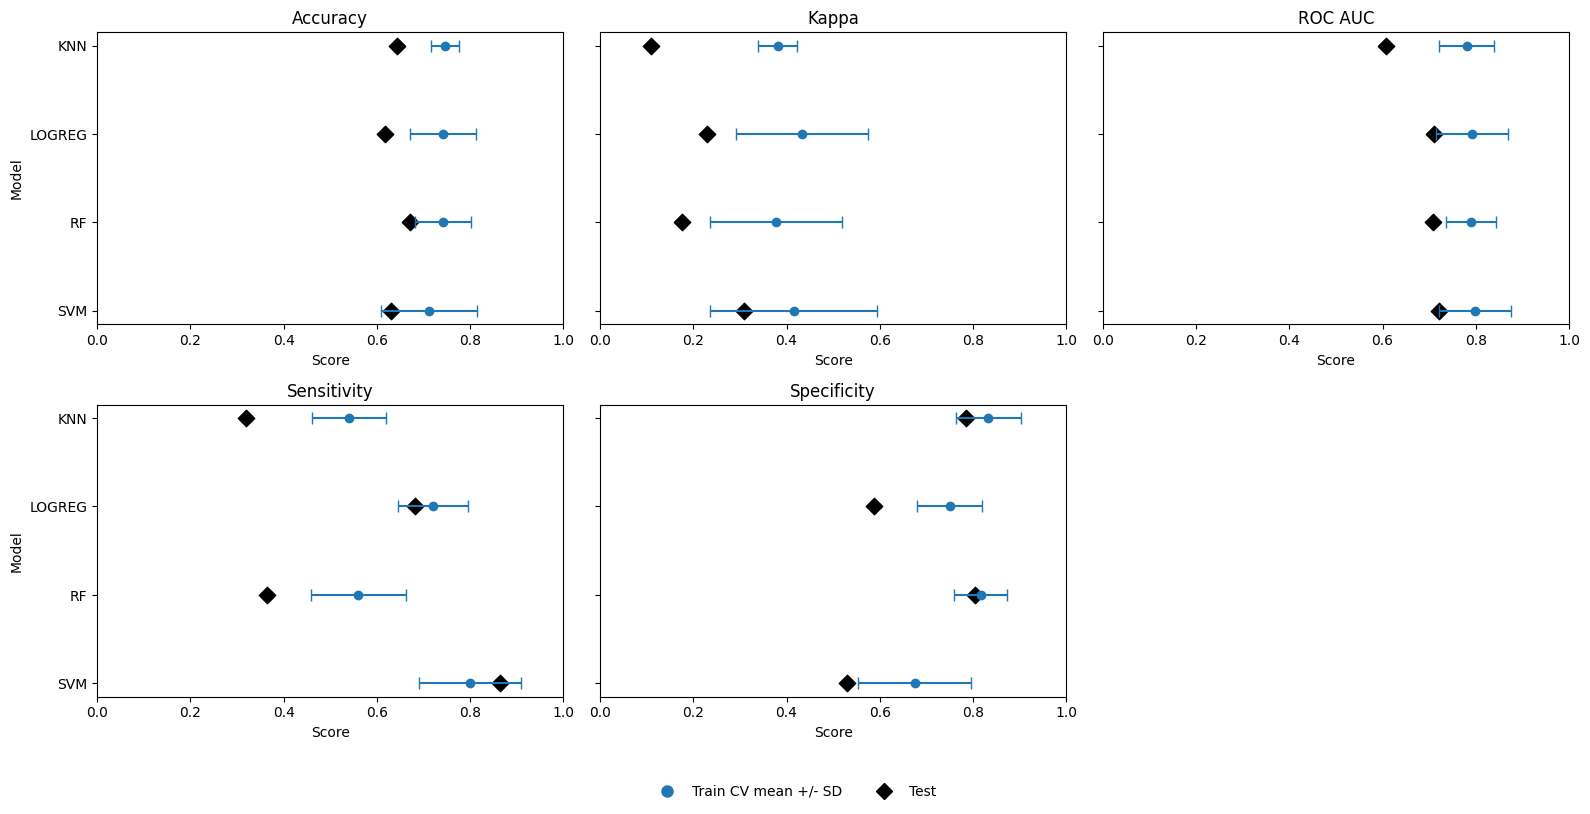

In [ ]:
# Join training/CV results
training_summary = metrics_summary_umap.copy()

# Test: performance_summary_umap has metrics as rows and models as columns
test_summary = performance_summary_umap.T.copy()

metrics_to_plot = {
    "Accuracy": {
        "cv_mean": "Accuracy_mean",
        "cv_sd": "Accuracy_sd",
        "test": "Accuracy"
    },
    "Kappa": {
        "cv_mean": "Kappa_mean",
        "cv_sd": "Kappa_sd",
        "test": "Kappa"
    },
    "ROC AUC": {
        "cv_mean": "ROC_AUC_mean",
        "cv_sd": "ROC_AUC_sd",
        "test": "AUC"
    },
    "Sensitivity": {
        "cv_mean": "Sensitivity_mean",
        "cv_sd": "Sensitivity_sd",
        "test": "Sensitivity"
    },
    "Specificity": {
        "cv_mean": "Specificity_mean",
        "cv_sd": "Specificity_sd",
        "test": "Specificity"
    }
}
plot_data = training_summary.copy()
plot_data["Model"] = training_summary.index

fig, axes = plt.subplots(
    2,
    3,
    figsize=(16, 8),
    sharey=True
)

axes = axes.flatten()

for ax, (metric_name, cols) in zip(axes, metrics_to_plot.items()):
    data = plot_data.sort_values(cols["cv_mean"]).copy()

    # Train / CV
    ax.errorbar(
        x=data[cols["cv_mean"]],
        y=data["Model"],
        xerr=data[cols["cv_sd"]],
        fmt="o",
        capsize=4,
        color="tab:blue",
        label="Train CV mean +/- SD"
    )

    # Test
    test_values = test_summary.loc[data["Model"], cols["test"]]

    ax.scatter(
        test_values,
        data["Model"],
        marker="D",
        s=70,
        color="black",
        label="Test"
    )

    ax.set_title(metric_name)
    ax.set_xlabel("Score")
    ax.set_xlim(0, 1)
    #ax.legend(loc="lower right")

axes[0].set_ylabel("Model")
axes[3].set_ylabel("Model")

# Turn off the empty panel, because there are 5 metrics and the grid has 6 slots
axes[-1].axis("off")

legend_elements = [
    Line2D(
        [0],
        [0],
        marker="o",
        color="tab:blue",
        label="Train CV mean +/- SD",
        linestyle="None",
        markersize=8
    ),
    Line2D(
        [0],
        [0],
        marker="D",
        color="black",
        label="Test",
        linestyle="None",
        markersize=8
    )
]

fig.legend(
    handles=legend_elements,
    loc="lower center",
    ncol=2,
    frameon=False,
    bbox_to_anchor=(0.5, -0.02)
)

plt.tight_layout(rect=[0, 0.05, 1, 1])
plt.show()

Ploting UMAP projections

In [ ]:
# Build plotting DataFrames
umap_train_plot = X_train_umap.copy()
umap_train_plot["Class"] = y_train.values
umap_train_plot["Set"] = "Train"

umap_test_plot = X_test_umap.copy()
umap_test_plot["Class"] = y_test.values
umap_test_plot["Set"] = "Test"

umap_plot_df = pd.concat(
    [umap_train_plot, umap_test_plot],
    axis=0
)

umap_plot_df["Class_label"] = umap_plot_df["Class"].map({
    0: "No recurrence",
    1: "Recurrence"
})

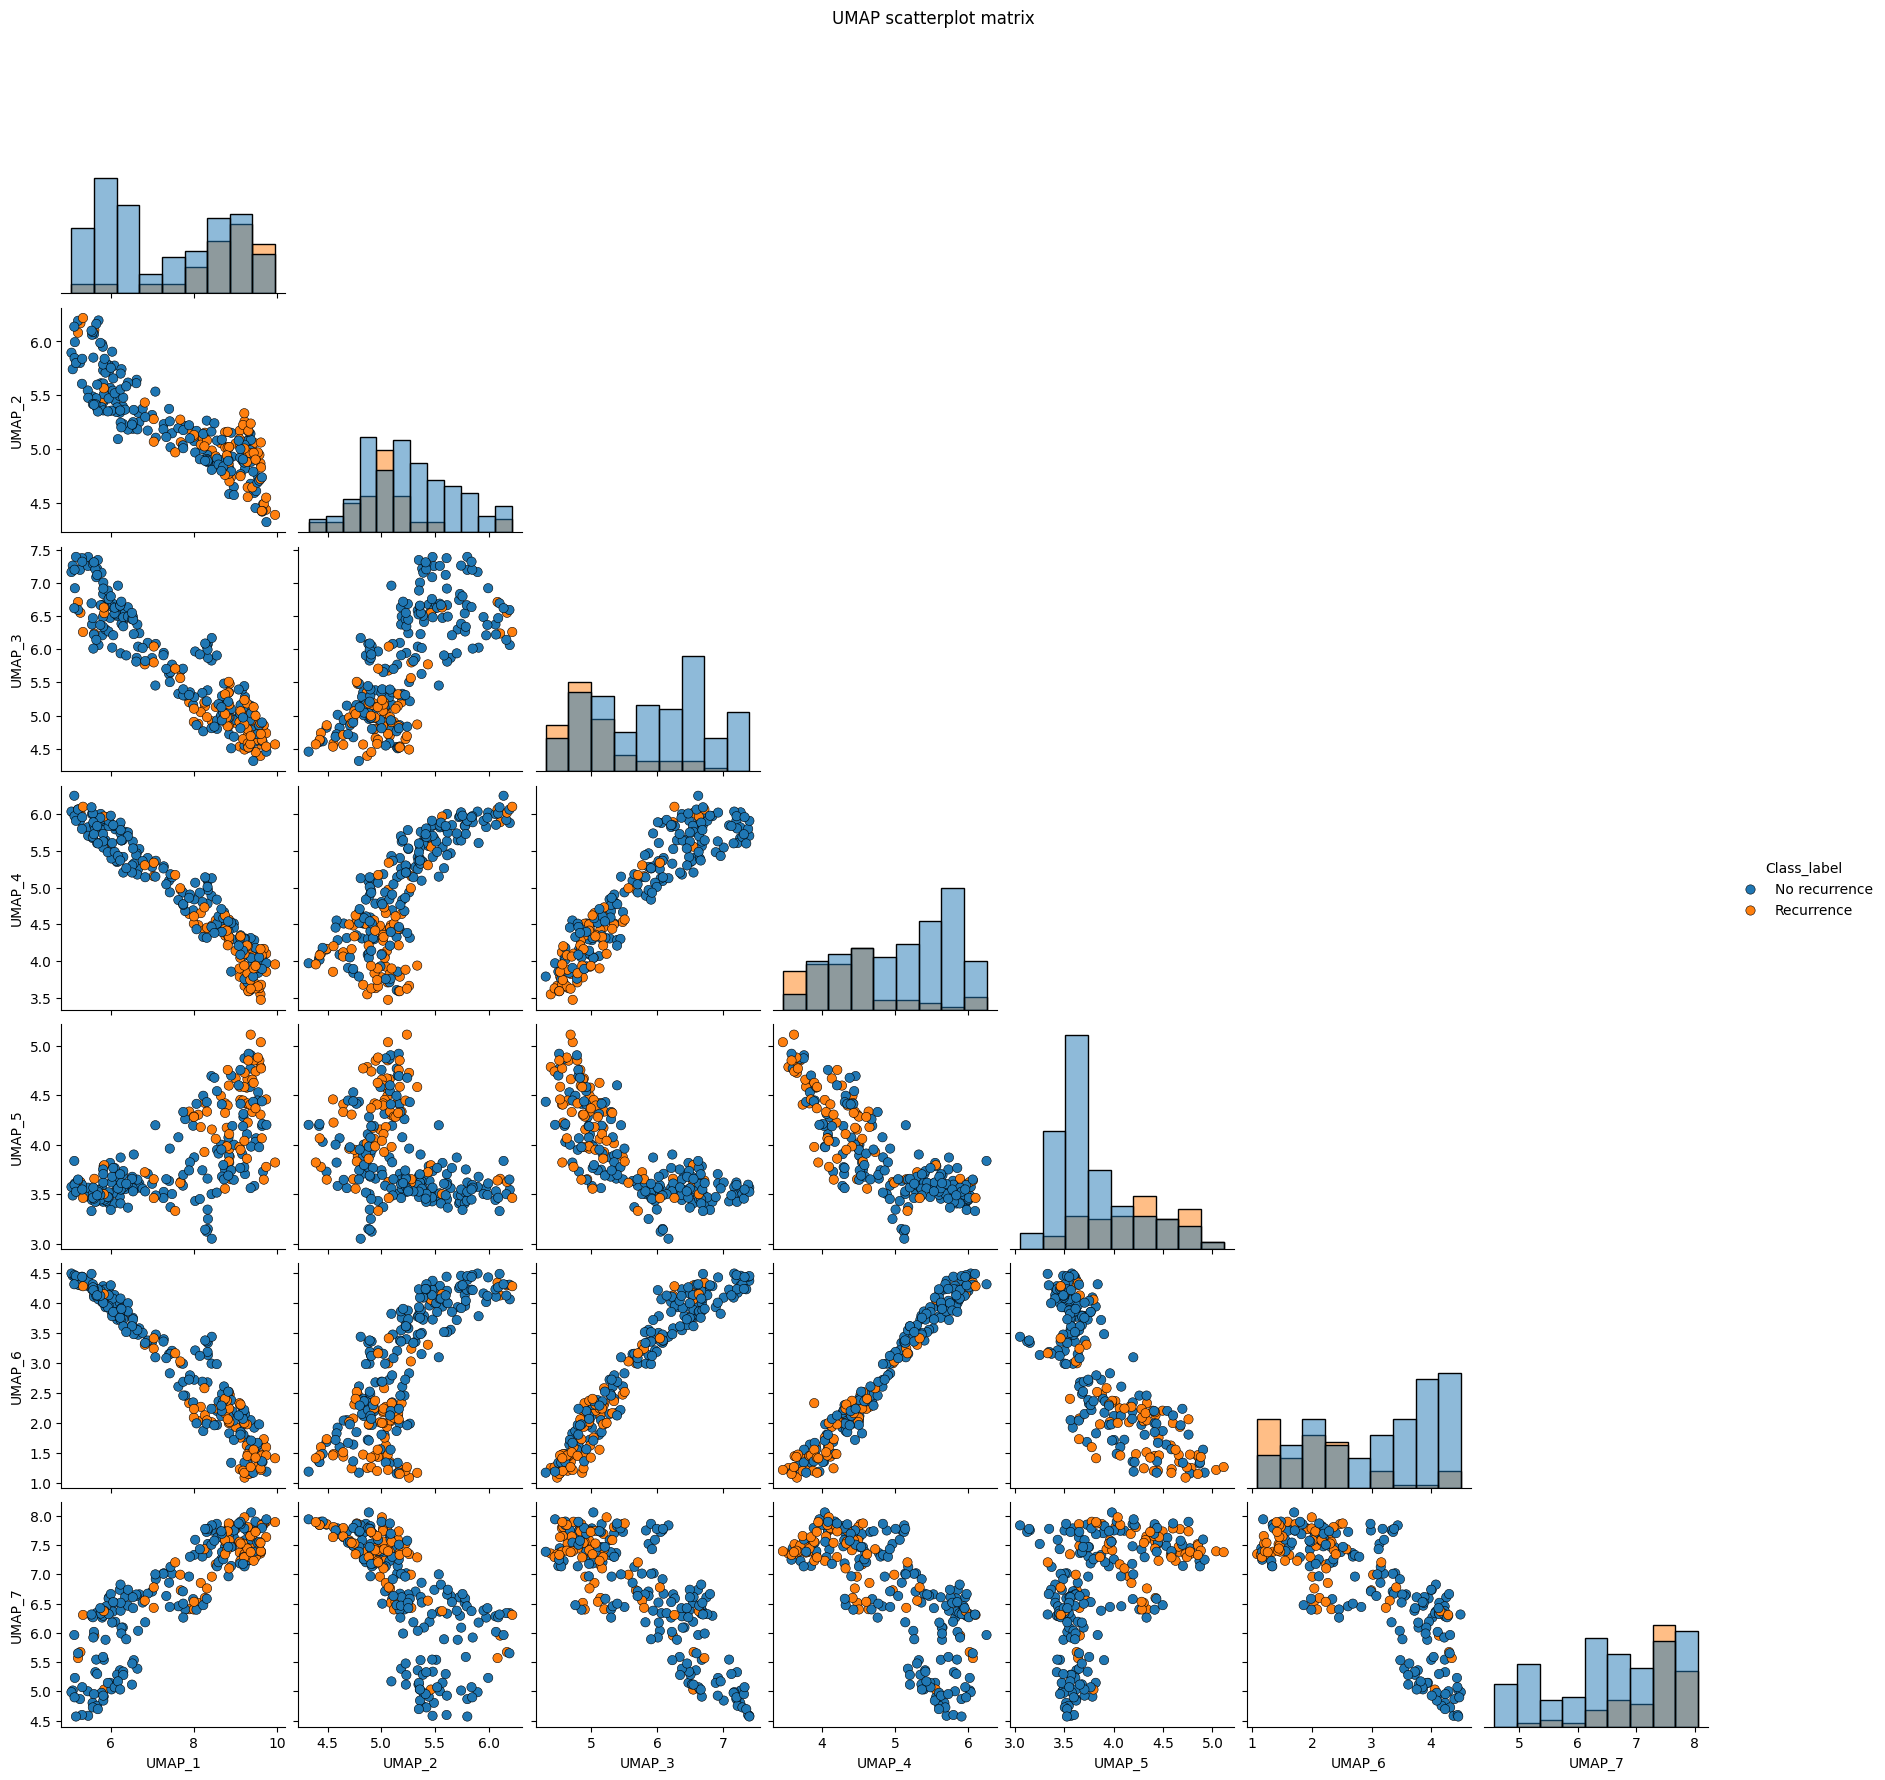

In [ ]:
umap_components_to_plot = ["UMAP_1", "UMAP_2", "UMAP_3", "UMAP_4", "UMAP_5", "UMAP_6", "UMAP_7"]#, "UMAP_8", "UMAP_9", "UMAP_10"]
sns.pairplot(
    data=umap_plot_df,
    vars=umap_components_to_plot,
    hue="Class_label",
    diag_kind="hist",
    corner=True,
    plot_kws={
        "s": 45,
        "edgecolor": "black",
        "linewidth": 0.4
    }
)

plt.suptitle(
    "UMAP scatterplot matrix",
    y=1.02
)

plt.show()

## Second approach: Deep autoencoder.

Learning the best low-dimensional representation for classification purposes.

Here, we will use all the features

In [ ]:
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import platform

from torch.utils.data import TensorDataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import accuracy_score, roc_auc_score, cohen_kappa_score, recall_score
from tqdm.notebook import tqdm

In [ ]:
if platform.system() == 'Darwin': #si es macOS
    av1 = torch.backends.mps.is_available()
    # this ensures that the current PyTorch installation was built with MPS activated.
    av2 = torch.backends.mps.is_built()
    if(av1==av2==True):
        print('MPS available?',av1,'MPS built?',av2)
        device = torch.device('mps')
    else:
        device = torch.device('cpu')
else:
    #Check if GPU is available
    if torch.cuda.is_available():
        device = torch.device('cuda')
    else:
        device = torch.device('cpu')
print("Device:",device)

Device: cuda


In [ ]:
# Reproducibility
random_seed = 420

np.random.seed(random_seed)
torch.manual_seed(random_seed)

In [ ]:
#genes_to_use = top_DGE_genes
#genes_to_use = bibliography_genes
#genes_to_use = top_var_genes
genes_to_use = gene_features  # Use all genes for the model

X_train = table_training[genes_to_use]
y_train = table_training["Class"]

X_test = table_testing[genes_to_use]
y_test = table_testing["Class"]

In [ ]:
# Scale data
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Convert to PyTorch tensors
X_train_tensor = torch.tensor(X_train_scaled, dtype=torch.float32).to(device)
X_test_tensor = torch.tensor(X_test_scaled, dtype=torch.float32).to(device)
y_train_tensor = torch.tensor(y_train.values, dtype=torch.float32).view(-1, 1).to(device)
y_test_tensor = torch.tensor(y_test.values, dtype=torch.float32).view(-1, 1).to(device)

# Create training dataset and dataloader
train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
train_loader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=True
)

Autoencoder architecture

In [ ]:
class ClassifierAutoencoder(nn.Module):
    def __init__(self, input_dim, latent_dim=32):
        super().__init__()

        self.encoder = nn.Sequential(
            nn.Linear(input_dim, 1200),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(1200, 1000),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(1000, 800),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(800, 500),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(500, latent_dim),
            nn.ReLU()
        )

        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 500),
            nn.ReLU(),
            nn.Linear(500, 800),
            nn.ReLU(),
            nn.Linear(800, 1000),
            nn.ReLU(),
            nn.Linear(1000, 1200),
            nn.ReLU(),
            nn.Linear(1200, input_dim)
        )

        self.classifier = nn.Sequential(
            nn.Linear(latent_dim, 32),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(32, 1)
        )

    def forward(self, x):
        z = self.encoder(x)
        x_reconstructed = self.decoder(z)
        class_logits = self.classifier(z)

        return x_reconstructed, class_logits, z

In [ ]:
input_dim = X_train_scaled.shape[1]

model = ClassifierAutoencoder(
    input_dim=input_dim,
    latent_dim=300
).to(device)

reconstruction_loss_fn = nn.MSELoss()
classification_loss_fn = nn.BCEWithLogitsLoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=1e-3,
    weight_decay=1e-4
)

num_epochs = 100

alpha = 0.2  # reconstruction loss weight
beta = 1.0 - alpha  # classification loss weight

In [ ]:
training_history = []

progress_bar = tqdm(range(num_epochs), desc="Training ClassifierAutoencoder")

for epoch in progress_bar:
    model.train()

    epoch_total_loss = 0
    epoch_reconstruction_loss = 0
    epoch_classification_loss = 0

    all_train_probs = []
    all_train_preds = []
    all_train_labels = []

    for batch_X, batch_y in train_loader:
        batch_X = batch_X.to(device)
        batch_y = batch_y.to(device)

        optimizer.zero_grad()

        X_reconstructed, class_logits, _ = model(batch_X)

        reconstruction_loss = reconstruction_loss_fn(X_reconstructed, batch_X)
        classification_loss = classification_loss_fn(class_logits, batch_y)

        total_loss = alpha * reconstruction_loss + beta * classification_loss

        total_loss.backward()
        optimizer.step()

        epoch_total_loss += total_loss.item()
        epoch_reconstruction_loss += reconstruction_loss.item()
        epoch_classification_loss += classification_loss.item()

        train_probs = torch.sigmoid(class_logits).detach().cpu().numpy().ravel()
        train_preds = (train_probs >= 0.5).astype(int)
        train_labels = batch_y.detach().cpu().numpy().ravel()

        all_train_probs.extend(train_probs)
        all_train_preds.extend(train_preds)
        all_train_labels.extend(train_labels)

    mean_total_loss = epoch_total_loss / len(train_loader)
    mean_reconstruction_loss = epoch_reconstruction_loss / len(train_loader)
    mean_classification_loss = epoch_classification_loss / len(train_loader)

    train_accuracy = accuracy_score(all_train_labels, all_train_preds)

    try:
        train_auc = roc_auc_score(all_train_labels, all_train_probs)
    except ValueError:
        train_auc = np.nan

    training_history.append({
        "epoch": epoch + 1,
        "total_loss": mean_total_loss,
        "reconstruction_loss": mean_reconstruction_loss,
        "classification_loss": mean_classification_loss,
        "train_accuracy": train_accuracy,
        "train_auc": train_auc
    })

    progress_bar.set_postfix({
        "loss": f"{mean_total_loss:.4f}",
        "class_loss": f"{mean_classification_loss:.4f}",
        "acc": f"{train_accuracy:.3f}",
        "auc": f"{train_auc:.3f}"
    })

training_history = pd.DataFrame(training_history)

display(training_history.tail())

Training ClassifierAutoencoder:   0%|          | 0/100 [00:00<?, ?it/s]

,epoch,total_loss,reconstruction_loss,classification_loss,train_accuracy,train_auc
95,96,0.182114,0.862815,0.011938,0.988235,1.000000
96,97,0.326981,0.861524,0.193345,0.994118,0.993667
97,98,0.181629,0.858851,0.012324,0.988235,0.999750
98,99,0.181108,0.839296,0.016561,0.982353,1.000000
99,100,0.184358,0.827996,0.023449,0.988235,1.000000


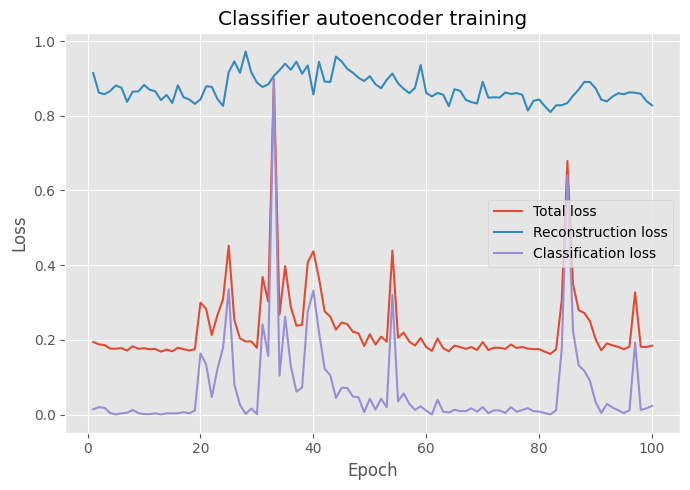

In [ ]:
plt.style.use("ggplot")

plt.figure(figsize=(7, 5))

plt.plot(training_history["epoch"], training_history["total_loss"], label="Total loss")
plt.plot(training_history["epoch"], training_history["reconstruction_loss"], label="Reconstruction loss")
plt.plot(training_history["epoch"], training_history["classification_loss"], label="Classification loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Classifier autoencoder training")
plt.legend()
plt.tight_layout()
plt.show()

In [ ]:
# Evaluate model on test set
model.eval()

with torch.no_grad():
    _, test_logits, test_latent = model(X_test_tensor)

    # Get probabilities and predictions
    test_prob = torch.sigmoid(test_logits).detach().cpu().numpy().ravel()
    test_pred = (test_prob >= 0.5).astype(int)

y_test_np = y_test.values

positive_class = 1
negative_class = 0

# Calculate and display evaluation metrics
autoencoder_results = {
    "AUC": roc_auc_score(y_test_np, test_prob),
    "Accuracy": accuracy_score(y_test_np, test_pred),
    "Kappa": cohen_kappa_score(y_test_np, test_pred),
    "Sensitivity": recall_score(y_test_np, test_pred, pos_label=positive_class),
    "Specificity": recall_score(y_test_np, test_pred, pos_label=negative_class)
}

autoencoder_results = pd.DataFrame(
    autoencoder_results,
    index=["Classifier_Autoencoder"]
)

display(autoencoder_results.round(3))

,AUC,Accuracy,Kappa,Sensitivity,Specificity
Classifier_Autoencoder,0.673,0.644,0.132,0.364,0.765


We can visualize the autoencoder's latent space, which was learned and used for classification

In [ ]:
model.eval()

with torch.no_grad():
    # Extract latent representations
    z_train = model.encoder(X_train_tensor.to(device))
    z_test = model.encoder(X_test_tensor.to(device))

# Convert to numpy and create DataFrames
z_train = z_train.detach().cpu().numpy()
z_test = z_test.detach().cpu().numpy()

z_train_df = pd.DataFrame(
    z_train,
    columns=[f"Latent_{i+1}" for i in range(z_train.shape[1])]
)

z_train_df["Class"] = list(y_train)
z_train_df["Set"] = "Train"

z_test_df = pd.DataFrame(
    z_test,
    columns=[f"Latent_{i+1}" for i in range(z_test.shape[1])]
)

z_test_df["Class"] = list(y_test)
z_test_df["Set"] = "Test"

# Concatenate and add class labels
latent_df = pd.concat(
    [z_train_df, z_test_df],
    axis=0,
    ignore_index=True
)

latent_df["Class_label"] = latent_df["Class"].map({
    0: "No recurrence",
    1: "Recurrence"
})

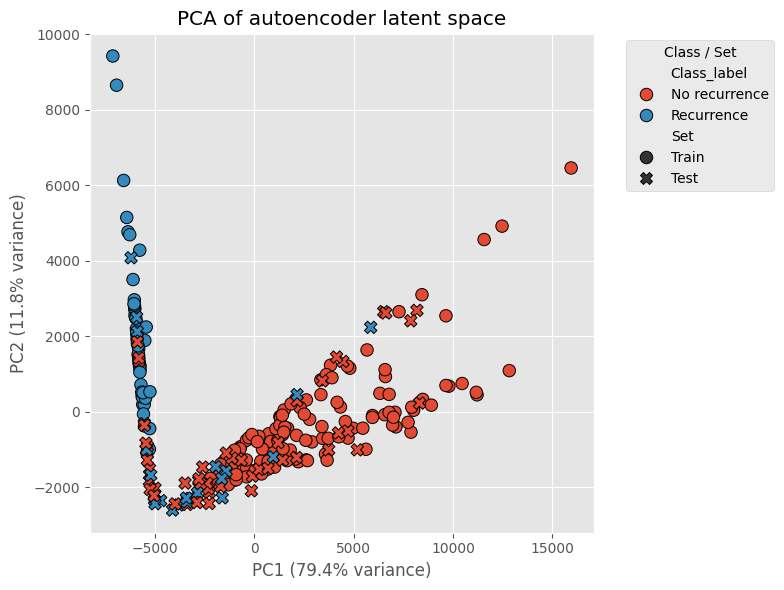

In [ ]:
from sklearn.decomposition import PCA

latent_features = latent_df.filter(regex="^Latent_")

pca_latent = PCA(n_components=2)
latent_pca = pca_latent.fit_transform(latent_features)

latent_pca_df = pd.DataFrame(
    latent_pca,
    columns=["PC1", "PC2"]
)

latent_pca_df["Class_label"] = latent_df["Class_label"]
latent_pca_df["Set"] = latent_df["Set"]

plt.figure(figsize=(8, 6))

sns.scatterplot(
    data=latent_pca_df,
    x="PC1",
    y="PC2",
    hue="Class_label",
    style="Set",
    s=80,
    edgecolor="black"
)

plt.title("PCA of autoencoder latent space")
plt.xlabel(f"PC1 ({pca_latent.explained_variance_ratio_[0] * 100:.1f}% variance)")
plt.ylabel(f"PC2 ({pca_latent.explained_variance_ratio_[1] * 100:.1f}% variance)")
plt.legend(title="Class / Set", bbox_to_anchor=(1.05, 1), loc="upper left")
plt.tight_layout()
plt.show()

### Additional improvement: early stopping to avoid overfitting.

In [ ]:
input_dim = X_train_scaled.shape[1]

model = ClassifierAutoencoder(
    input_dim=input_dim,
    latent_dim=300
).to(device)

reconstruction_loss_fn = nn.MSELoss()
classification_loss_fn = nn.BCEWithLogitsLoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=1e-3,
    weight_decay=1e-4
)

alpha = 1.0  # reconstruction loss weight
beta = 1.0 #- alpha  # classification loss weight

In [ ]:
from sklearn.model_selection import train_test_split
from torch.utils.data import TensorDataset, DataLoader

random_seed = 123
np.random.seed(random_seed)
torch.manual_seed(random_seed)

# Split training data into inner training and validation sets
X_train_inner, X_val, y_train_inner, y_val = train_test_split(
    X_train_scaled,
    y_train,
    test_size=0.2,
    random_state=random_seed,
    stratify=y_train
)

# Convert to PyTorch tensors for inner training and validation
X_train_inner_tensor = torch.tensor(X_train_inner, dtype=torch.float32).to(device)
y_train_inner_tensor = torch.tensor(y_train_inner.values, dtype=torch.float32).view(-1, 1).to(device)

X_val_tensor = torch.tensor(X_val, dtype=torch.float32).to(device)
y_val_tensor = torch.tensor(y_val.values, dtype=torch.float32).view(-1, 1).to(device)

# Create inner training dataset and dataloader
train_inner_dataset = TensorDataset(X_train_inner_tensor, y_train_inner_tensor)

train_loader = DataLoader(
    train_inner_dataset,
    batch_size=32,
    shuffle=True
)

In [ ]:
import copy
from tqdm.notebook import tqdm

num_epochs = 500
patience = 50
min_delta = 1e-4

best_val_loss = float("inf")
best_val_classification_loss = float("inf")
best_model_state = None
epochs_without_improvement = 0
best_epoch = None

training_history = []

progress_bar = tqdm(range(num_epochs), desc="Training with early stopping")

for epoch in progress_bar:
    model.train()

    epoch_total_loss = 0
    epoch_reconstruction_loss = 0
    epoch_classification_loss = 0

    for batch_X, batch_y in train_loader:
        optimizer.zero_grad()

        X_reconstructed, class_logits, _ = model(batch_X)

        reconstruction_loss = reconstruction_loss_fn(X_reconstructed, batch_X)
        classification_loss = classification_loss_fn(class_logits, batch_y)

        total_loss = alpha * reconstruction_loss + beta * classification_loss

        total_loss.backward()
        optimizer.step()

        epoch_total_loss += total_loss.item()
        epoch_reconstruction_loss += reconstruction_loss.item()
        epoch_classification_loss += classification_loss.item()

    train_total_loss = epoch_total_loss / len(train_loader)
    train_reconstruction_loss = epoch_reconstruction_loss / len(train_loader)
    train_classification_loss = epoch_classification_loss / len(train_loader)

    # Evaluate on validation set
    model.eval()

    with torch.no_grad():
        X_val_reconstructed, val_logits, _ = model(X_val_tensor)

        val_reconstruction_loss = reconstruction_loss_fn(
            X_val_reconstructed,
            X_val_tensor
        )

        val_classification_loss = classification_loss_fn(
            val_logits,
            y_val_tensor
        )

        val_total_loss = (
            alpha * val_reconstruction_loss +
            beta * val_classification_loss
        )

    val_total_loss_value = val_total_loss.item()
    val_classification_loss_value = val_classification_loss.item()

    training_history.append({
        "epoch": epoch + 1,
        "train_total_loss": train_total_loss,
        "train_reconstruction_loss": train_reconstruction_loss,
        "train_classification_loss": train_classification_loss,
        "val_total_loss": val_total_loss_value,
        "val_reconstruction_loss": val_reconstruction_loss.item(),
        "val_classification_loss": val_classification_loss.item()
    })

    progress_bar.set_postfix({
        "train_loss": f"{train_total_loss:.4f}",
        "val_loss": f"{val_total_loss_value:.4f}",
        "val_class_loss": f"{val_classification_loss_value:.4f}",
        "patience": epochs_without_improvement
    })

    # Early stopping logic based on validation classification loss
    if val_classification_loss_value < best_val_classification_loss - min_delta:
        best_val_classification_loss = val_classification_loss_value
        best_model_state = copy.deepcopy(model.state_dict())
        best_epoch = epoch + 1
        epochs_without_improvement = 0
    else:
        epochs_without_improvement += 1

    if epochs_without_improvement >= patience:
        print(f"Early stopping at epoch {epoch + 1}")
        break

# Restore best model weights
model.load_state_dict(best_model_state)

training_history = pd.DataFrame(training_history)

display(training_history.tail())

Training with early stopping:   0%|          | 0/500 [00:00<?, ?it/s]

Early stopping at epoch 98


,epoch,train_total_loss,train_reconstruction_loss,train_classification_loss,val_total_loss,val_reconstruction_loss,val_classification_loss
93,94,0.792079,0.791167,0.000912,5.149618,0.800187,4.349432
94,95,0.796557,0.787694,0.008863,3.689311,0.801529,2.887782
95,96,0.801782,0.801486,0.000296,4.477769,0.813823,3.663945
96,97,0.858752,0.789267,0.069484,3.850790,0.807179,3.043611
97,98,0.824883,0.810783,0.014099,3.692025,0.799638,2.892387


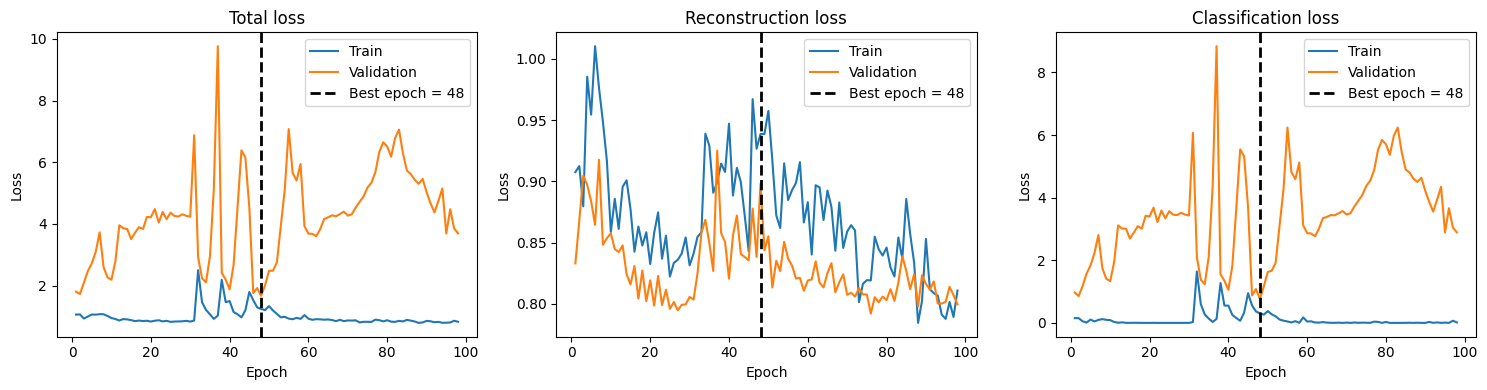

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

loss_pairs = {
    "Total loss": ("train_total_loss", "val_total_loss"),
    "Reconstruction loss": ("train_reconstruction_loss", "val_reconstruction_loss"),
    "Classification loss": ("train_classification_loss", "val_classification_loss")
}

for ax, (title, (train_col, val_col)) in zip(axes, loss_pairs.items()):
    # Plot training and validation losses
    ax.plot(
        training_history["epoch"],
        training_history[train_col],
        label="Train"
    )

    ax.plot(
        training_history["epoch"],
        training_history[val_col],
        label="Validation"
    )

    # Mark the best epoch
    ax.axvline(
        x=best_epoch,
        color="black",
        linestyle="--",
        linewidth=2,
        label=f"Best epoch = {best_epoch}"
    )

    ax.set_title(title)
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Loss")
    ax.legend()

plt.tight_layout()
plt.show()

In [ ]:
# Evaluate final model on test set
model.eval()

with torch.no_grad():
    _, test_logits, test_latent = model(X_test_tensor)

    # Get probabilities and predictions
    test_prob = torch.sigmoid(test_logits).detach().cpu().numpy().ravel()
    test_pred = (test_prob >= 0.5).astype(int)

y_test_np = y_test.values

positive_class = 1
negative_class = 0

# Calculate and display evaluation metrics
autoencoder_results = {
    "AUC": roc_auc_score(y_test_np, test_prob),
    "Accuracy": accuracy_score(y_test_np, test_pred),
    "Kappa": cohen_kappa_score(y_test_np, test_pred),
    "Sensitivity": recall_score(y_test_np, test_pred, pos_label=positive_class),
    "Specificity": recall_score(y_test_np, test_pred, pos_label=negative_class)
}

autoencoder_results = pd.DataFrame(
    autoencoder_results,
    index=["Classifier_Autoencoder"]
)

display(autoencoder_results.round(3))

,AUC,Accuracy,Kappa,Sensitivity,Specificity
Classifier_Autoencoder,0.742,0.699,0.202,0.318,0.863


Plot the 2-D projection of the latent space for best model choosen by early stopping

In [ ]:
model.eval()

with torch.no_grad():
    # Extract latent representations
    z_train = model.encoder(X_train_tensor.to(device))
    z_test = model.encoder(X_test_tensor.to(device))

# Convert to numpy and create DataFrames
z_train = z_train.detach().cpu().numpy()
z_test = z_test.detach().cpu().numpy()

z_train_df = pd.DataFrame(
    z_train,
    columns=[f"Latent_{i+1}" for i in range(z_train.shape[1])]
)

z_train_df["Class"] = list(y_train)
z_train_df["Set"] = "Train"

z_test_df = pd.DataFrame(
    z_test,
    columns=[f"Latent_{i+1}" for i in range(z_test.shape[1])]
)

z_test_df["Class"] = list(y_test)
z_test_df["Set"] = "Test"

# Concatenate and add class labels
latent_df = pd.concat(
    [z_train_df, z_test_df],
    axis=0,
    ignore_index=True
)

latent_df["Class_label"] = latent_df["Class"].map({
    0: "No recurrence",
    1: "Recurrence"
})

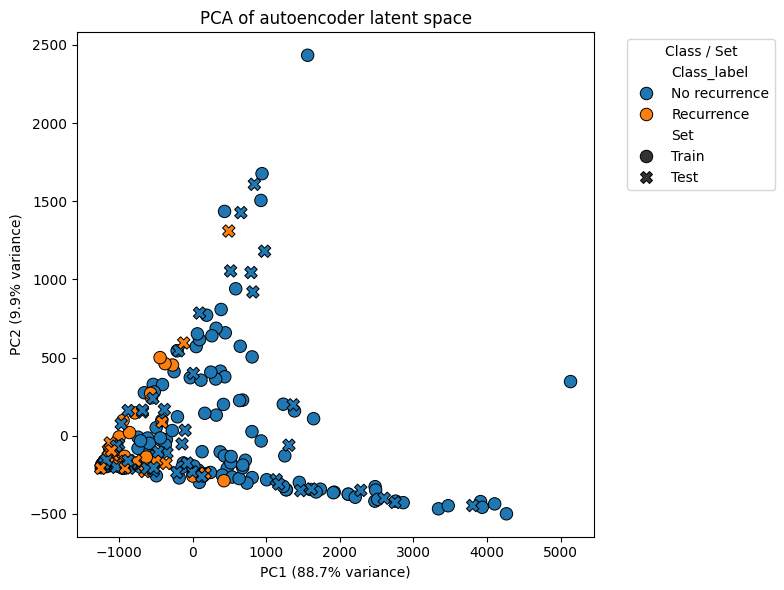

In [ ]:
latent_features = latent_df.filter(regex="^Latent_")

pca_latent = PCA(n_components=2)
latent_pca = pca_latent.fit_transform(latent_features)

latent_pca_df = pd.DataFrame(
    latent_pca,
    columns=["PC1", "PC2"]
)

latent_pca_df["Class_label"] = latent_df["Class_label"]
latent_pca_df["Set"] = latent_df["Set"]

plt.figure(figsize=(8, 6))

sns.scatterplot(
    data=latent_pca_df,
    x="PC1",
    y="PC2",
    hue="Class_label",
    style="Set",
    s=80,
    edgecolor="black"
)

plt.title("PCA of autoencoder latent space")
plt.xlabel(f"PC1 ({pca_latent.explained_variance_ratio_[0] * 100:.1f}% variance)")
plt.ylabel(f"PC2 ({pca_latent.explained_variance_ratio_[1] * 100:.1f}% variance)")
plt.legend(title="Class / Set", bbox_to_anchor=(1.05, 1), loc="upper left")
plt.tight_layout()
plt.show()